**Business Problem**

1. Which patient groups have more recorded doctor visits?
2. How are illness and health status associated with the visits?
3. Do chronic conditions corresponds to different visit patterns?
4. What should management investigate before making operational changes?


**Column Descriptions**

1. **`visits`**: Number of doctor visits in past 2 weeks.
2. **`gender`**: Gender of patient (`female`, `male`).
3. **`age`**: Age of patient in years (scaled; e.g., divided by 100).
4. **`income`**: Annual income (scaled; in tens of thousands of dollars).
5. **`illness`**: Number of illnesses in past 2 weeks.
6. **`reduced`**: Number of days of reduced activity in past 2 weeks due to illness or injury.
7. **`health`**: General health questionnaire score (higher score indicates poorer health).
8. **`private`**: Has private health insurance? (`yes`, `no`)
9. **`freepoor`**: Has free health cover due to low income? (`yes`, `no`)
10. **`freerepat`**: Has free health cover due to old age, disability or veteran status? (`yes`, `no`)
11. **`nchronic`**: Has a non-chronic condition limiting activity? (`yes`, `no`)
12. **`lchronic`**: Has a chronic condition limiting activity? (`yes`, `no`)

**Importing Libraries**

In [1]:
#importing libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

**Importing Dataset**

In [2]:
#importing dataset

df = pd.read_csv("/content/1776250375-P2-Healthcare Analytics for Doctor Visits.csv")

**Understanding Data**

In [3]:
#first 5 rows

df.head()

,Unnamed: 0,visits,gender,age,income,illness,reduced,health,private,freepoor,freerepat,nchronic,lchronic
0,1,1,female,0.19,0.55,1,4,1,yes,no,no,no,no
1,2,1,female,0.19,0.45,1,2,1,yes,no,no,no,no
2,3,1,male,0.19,0.90,3,0,0,no,no,no,no,no
3,4,1,male,0.19,0.15,1,0,0,no,no,no,no,no
4,5,1,male,0.19,0.45,2,5,1,no,no,no,yes,no


In [4]:
#last 5 rows

df.tail()

,Unnamed: 0,visits,gender,age,income,illness,reduced,health,private,freepoor,freerepat,nchronic,lchronic
5185,5186,0,female,0.22,0.55,0,0,0,no,no,no,no,no
5186,5187,0,male,0.27,1.30,0,0,1,no,no,no,no,no
5187,5188,0,female,0.37,0.25,1,0,1,no,no,yes,no,no
5188,5189,0,female,0.52,0.65,0,0,0,no,no,no,no,no
5189,5190,0,male,0.72,0.25,0,0,0,no,no,yes,no,no


In [5]:
#number of rows and columns

df.shape

(5190, 13)

In [6]:
#dataset information

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5190 entries, 0 to 5189
Data columns (total 13 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Unnamed: 0  5190 non-null   int64  
 1   visits      5190 non-null   int64  
 2   gender      5190 non-null   object 
 3   age         5190 non-null   float64
 4   income      5190 non-null   float64
 5   illness     5190 non-null   int64  
 6   reduced     5190 non-null   int64  
 7   health      5190 non-null   int64  
 8   private     5190 non-null   object 
 9   freepoor    5190 non-null   object 
 10  freerepat   5190 non-null   object 
 11  nchronic    5190 non-null   object 
 12  lchronic    5190 non-null   object 
dtypes: float64(2), int64(5), object(6)
memory usage: 527.2+ KB


In [7]:
#statistical information

df.describe()

,Unnamed: 0,visits,age,income,illness,reduced,health
count,5190.000000,5190.000000,5190.000000,5190.000000,5190.000000,5190.000000,5190.000000
mean,2595.500000,0.301734,0.406385,0.583160,1.431985,0.861850,1.217534
std,1498.368279,0.798134,0.204782,0.368907,1.384152,2.887628,2.124266
min,1.000000,0.000000,0.190000,0.000000,0.000000,0.000000,0.000000
25%,1298.250000,0.000000,0.220000,0.250000,0.000000,0.000000,0.000000
50%,2595.500000,0.000000,0.320000,0.550000,1.000000,0.000000,0.000000
75%,3892.750000,0.000000,0.620000,0.900000,2.000000,0.000000,2.000000
max,5190.000000,9.000000,0.720000,1.500000,5.000000,14.000000,12.000000


In [8]:
#checking duplicates

duplicate_count = df.duplicated().sum()
print('Number of duplicates =', duplicate_count)

Number of duplicates = 0


In [9]:
#checking nulls

null_count = df.isnull().sum()
print('Number of nulls =', null_count)

Number of nulls = Unnamed: 0    0
visits        0
gender        0
age           0
income        0
illness       0
reduced       0
health        0
private       0
freepoor      0
freerepat     0
nchronic      0
lchronic      0
dtype: int64


**Exploratory Data Analysis (EDA)**


**Univariate Analysis**

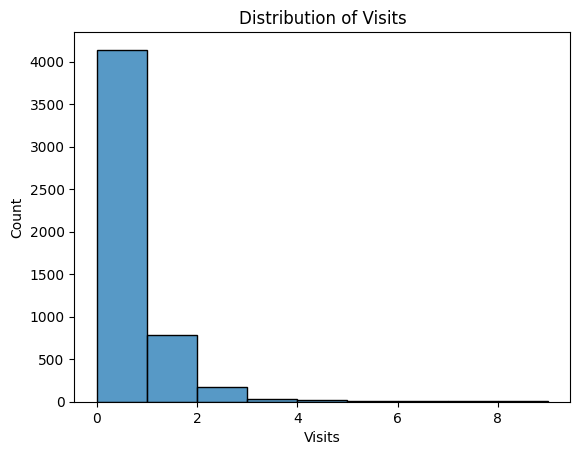

<Figure size 640x480 with 0 Axes>

In [10]:
#Visit Analysis

sns.histplot(x='visits',data = df,bins=9)
plt.xlabel('Visits')
plt.ylabel('Count')
plt.title('Distribution of Visits')
plt.show()
plt.tight_layout()

Insight : More than 4000 patients recorded 0 visits in past 2 weeks, indicating health conditions not requiring frequent visists.

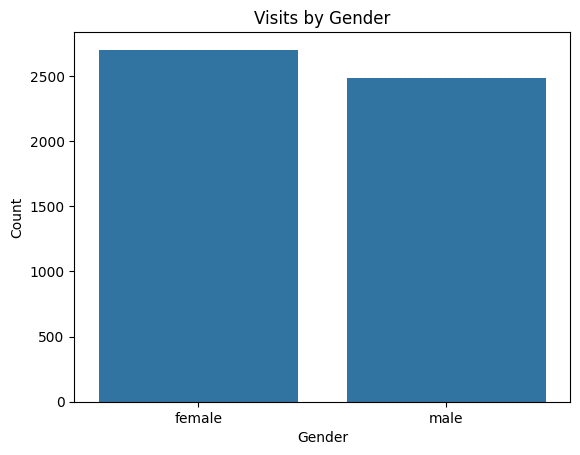

<Figure size 640x480 with 0 Axes>

In [11]:
#Visits by Gender

sns.countplot(x='gender',data = df)
plt.xlabel('Gender')
plt.ylabel('Count')
plt.title('Visits by Gender')
plt.show()
plt.tight_layout()

Insight : Females record a higher number of visits as compared to males.

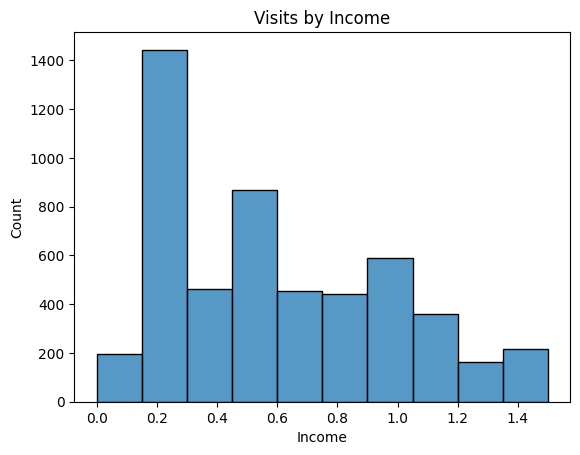

<Figure size 640x480 with 0 Axes>

In [12]:
#visists by income

sns.histplot(x='income',data = df,bins=10)
plt.xlabel('Income')
plt.ylabel('Count')
plt.title('Visits by Income')
plt.show()
plt.tight_layout()

Insight : Lower income groups show frequent visits.

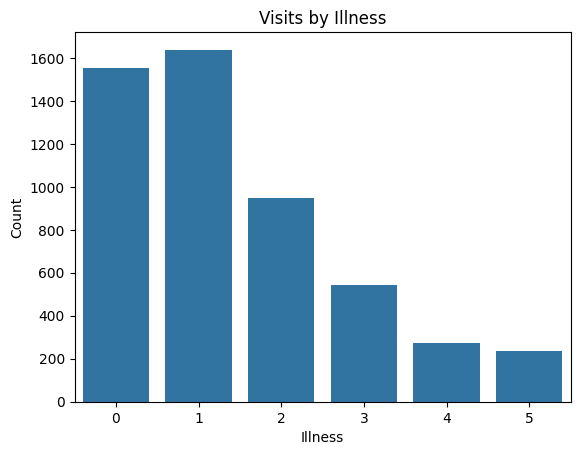

<Figure size 640x480 with 0 Axes>

In [13]:
#Visits by Illness

sns.countplot(x='illness',data = df)
plt.xlabel('Illness')
plt.ylabel('Count')
plt.title('Visits by Illness')
plt.show()
plt.tight_layout()

Insight : Patients with less(0-1) illness counts for the majority of hospital visits in past 2 weeks.

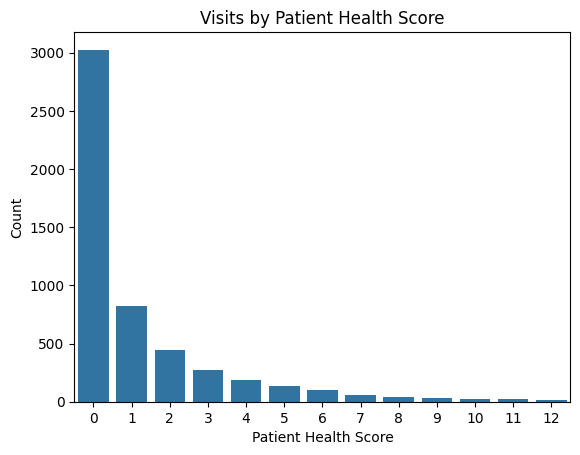

<Figure size 640x480 with 0 Axes>

In [14]:
#Visits by Patient Health Score

sns.countplot(x='health',data = df)
plt.xlabel('Patient Health Score')
plt.ylabel('Count')
plt.title('Visits by Patient Health Score')
plt.show()
plt.tight_layout()

Insight : In past 2 weeks, patients with 0 health score (healthy individuals) contribute to highest doctor visits, with comparatively lesser patients with poorer health.

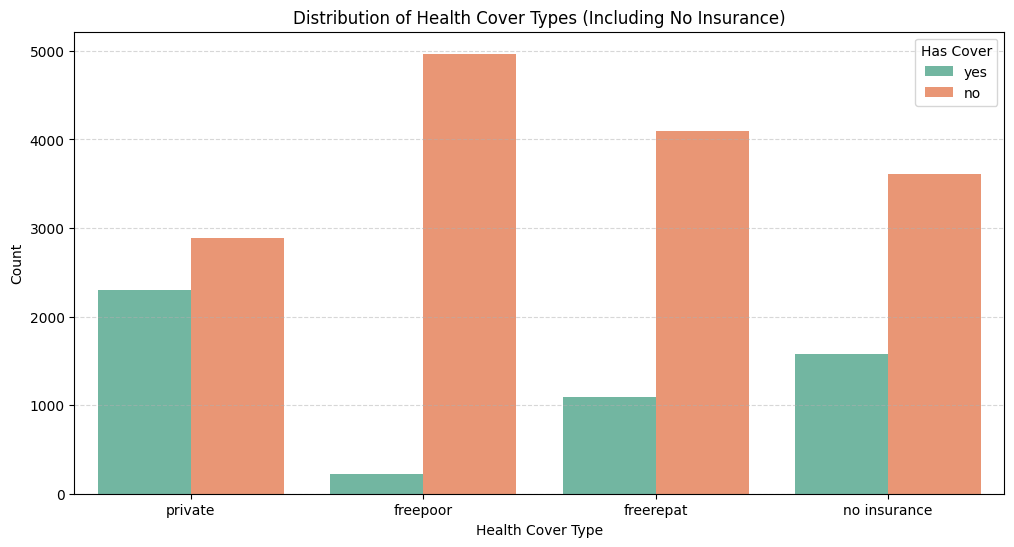

In [15]:
#Visits by Health Cover

# Calculate who has no coverage at all (neither private, freepoor, nor freerepat)
none_cover = ((df['private'] == 'no') & (df['freepoor'] == 'no') & (df['freerepat'] == 'no')).map({True: 'yes', False: 'no'})

# Create a temporary dataframe with this new category
no_insurance_df = pd.DataFrame({
    'visits': df['visits'],
    'Cover Type': 'no insurance',
    'Has Cover': none_cover
})

# Melt the existing columns
cover_df = df.melt(id_vars=['visits'], value_vars=['private', 'freepoor', 'freerepat'],
                   var_name='Cover Type', value_name='Has Cover')

# Combine with the new category
combined_cover_df = pd.concat([cover_df, no_insurance_df], ignore_index=True)

plt.figure(figsize=(12, 6))
sns.countplot(data=combined_cover_df, x='Cover Type', hue='Has Cover', palette='Set2')
plt.xlabel('Health Cover Type')
plt.ylabel('Count')
plt.title('Distribution of Health Cover Types (Including No Insurance)')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.show()

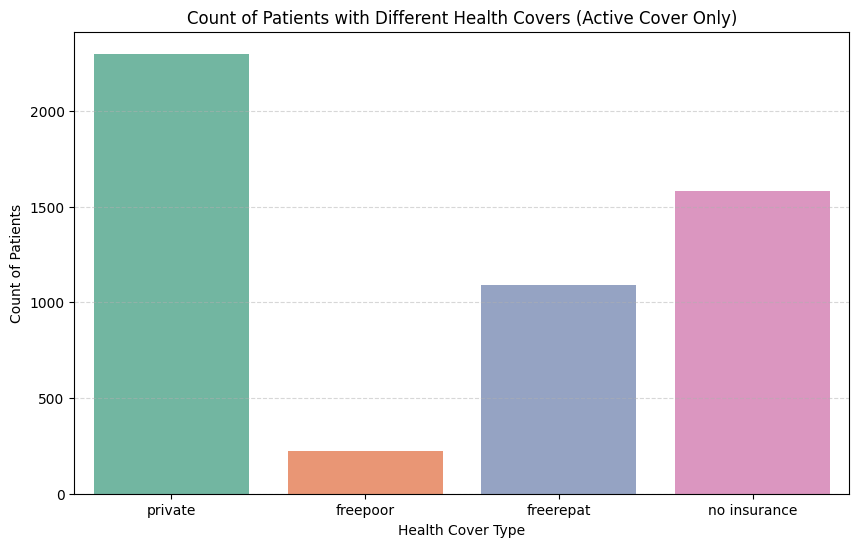

In [16]:
# Filter the combined health cover data to show only patients who actually possess the covers ('yes')
active_covers_df = combined_cover_df[combined_cover_df['Has Cover'] == 'yes']

# Create a count plot displaying only those with active health covers, specifying hue and legend to avoid warnings
plt.figure(figsize=(10, 6))
sns.countplot(
    data=active_covers_df,
    x='Cover Type',
    hue='Cover Type',
    palette='Set2',
    order=['private', 'freepoor', 'freerepat', 'no insurance'],
    legend=False
)

plt.xlabel('Health Cover Type')
plt.ylabel('Count of Patients')
plt.title('Count of Patients with Different Health Covers (Active Cover Only)')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.show()

Insight : More than 2000 patients visiting have private health cover, whereas majority of patients are not covered with any insurance.

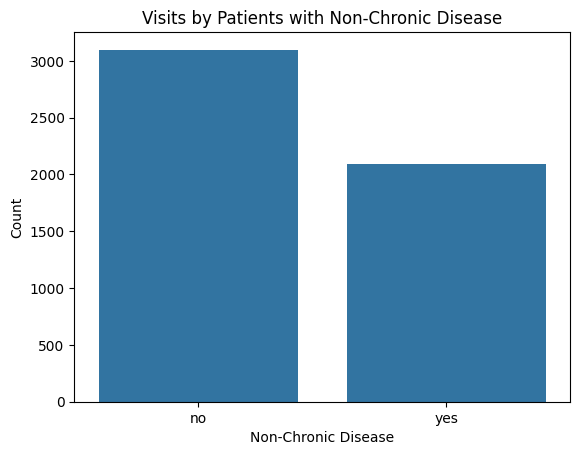

<Figure size 640x480 with 0 Axes>

In [21]:
#Visits by Patients with Non-Chronic Disease

sns.countplot(x='nchronic',data = df)
plt.xlabel('Non-Chronic Disease')
plt.ylabel('Count')
plt.title('Visits by Patients with Non-Chronic Disease')
plt.show()
plt.tight_layout()

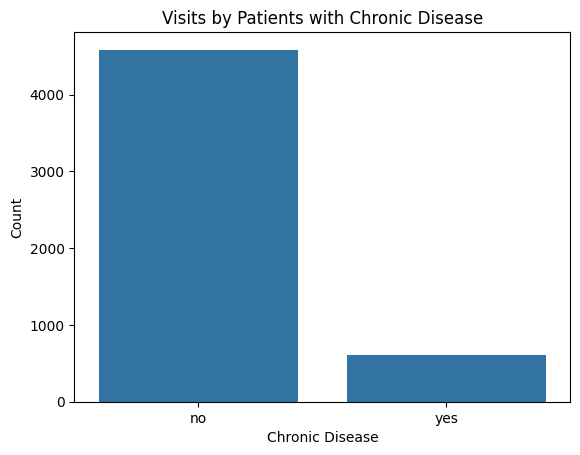

<Figure size 640x480 with 0 Axes>

In [22]:
#Visits by Patients with Chronic Disease

sns.countplot(x='lchronic',data = df)
plt.xlabel('Chronic Disease')
plt.ylabel('Count')
plt.title('Visits by Patients with Chronic Disease')
plt.show()
plt.tight_layout()

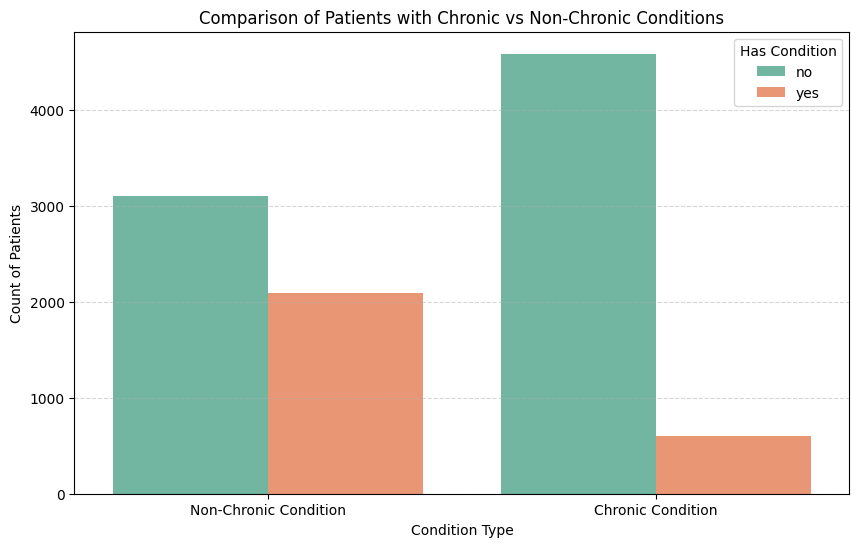

In [23]:
# Melting the dataframe to combine nchronic and lchronic for a single comparison plot
chronic_compare_df = df.melt(id_vars=['Unnamed: 0'], value_vars=['nchronic', 'lchronic'],
                             var_name='Condition Type', value_name='Has Condition')

# Mapping for clearer labels
chronic_compare_df['Condition Type'] = chronic_compare_df['Condition Type'].map({
    'nchronic': 'Non-Chronic Condition',
    'lchronic': 'Chronic Condition'
})

plt.figure(figsize=(10, 6))
sns.countplot(data=chronic_compare_df, x='Condition Type', hue='Has Condition', palette='Set2')
plt.xlabel('Condition Type')
plt.ylabel('Count of Patients')
plt.title('Comparison of Patients with Chronic vs Non-Chronic Conditions')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.show()

Insight : Around 2100 patients suffer from non-chronic condition limiting activity, whereas only 600 paients suffer from chronic conditions limiting activity.

**Bivariate Analysis**

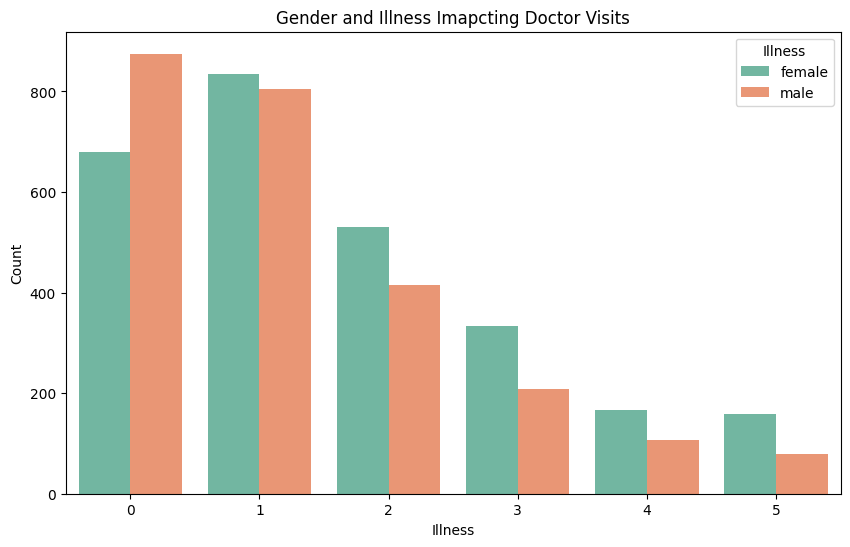

In [26]:
#Gender and Illness Imapcting Doctor Visits

plt.figure(figsize=(10, 6))
sns.countplot(data=df, x='illness', hue='gender', palette='Set2')
plt.xlabel('Illness')
plt.ylabel('Count')
plt.title('Gender and Illness Imapcting Doctor Visits')
plt.legend(title='Illness', loc='upper right')
plt.show()

Insight : Males show a initial higher visits with number of visits contardictily dropping with growing health issues.

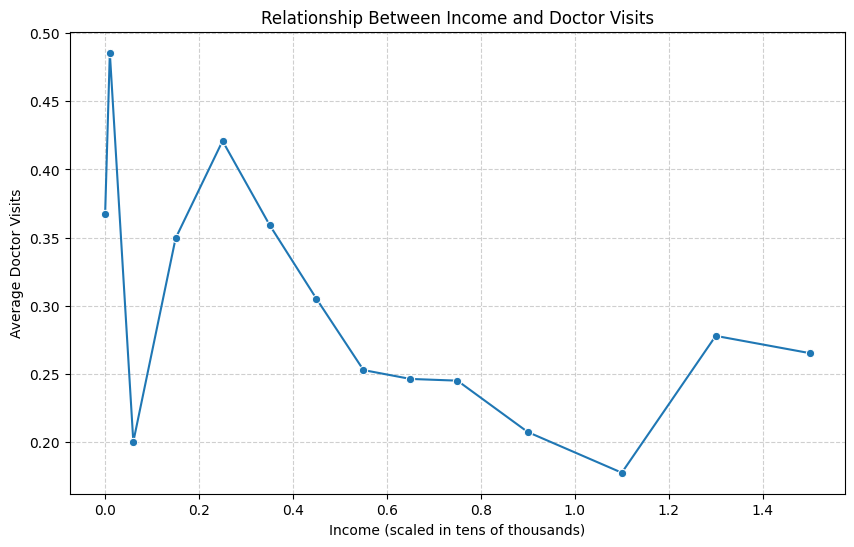

In [17]:
#Income Impacting Doctor Visits

plt.figure(figsize=(10, 6))
sns.lineplot(data=df, x='income', y='visits', marker='o', errorbar=None)
plt.xlabel('Income (scaled in tens of thousands)')
plt.ylabel('Average Doctor Visits')
plt.title('Relationship Between Income and Doctor Visits')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

Insight : Extreme lower income group show the highest number of doctor visits, with a sudden drop in visits, moderate income group showing intially higher visits with visits gradually dropping.  

/tmp/ipykernel_3788/24216794.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='nchronic', y='income', palette='Set2')


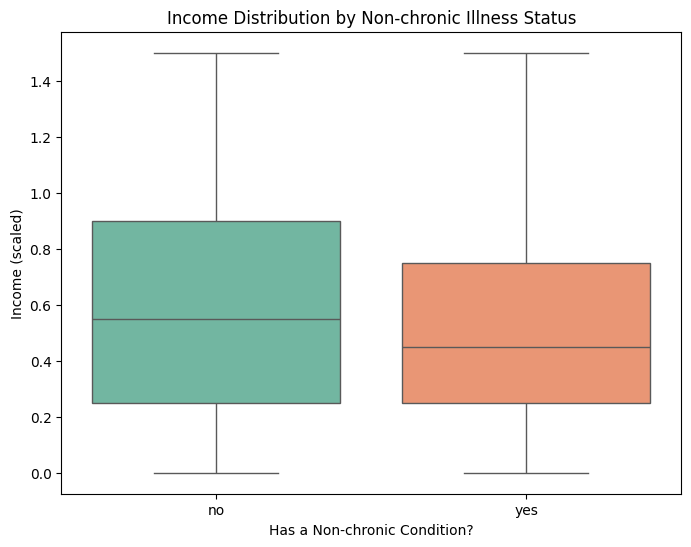

In [19]:
# Income Distribution by Non-chronic Illness Status

plt.figure(figsize=(8, 6))
sns.boxplot(data=df, x='nchronic', y='income', palette='Set2')
plt.xlabel('Has a Non-chronic Condition?')
plt.ylabel('Income (scaled)')
plt.title('Income Distribution by Non-chronic Illness Status')
plt.show()

Insight : Lower income group patients are more likely to be associated with non-chronic illness.

/tmp/ipykernel_3788/2300130365.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='lchronic', y='income', palette='Set2')


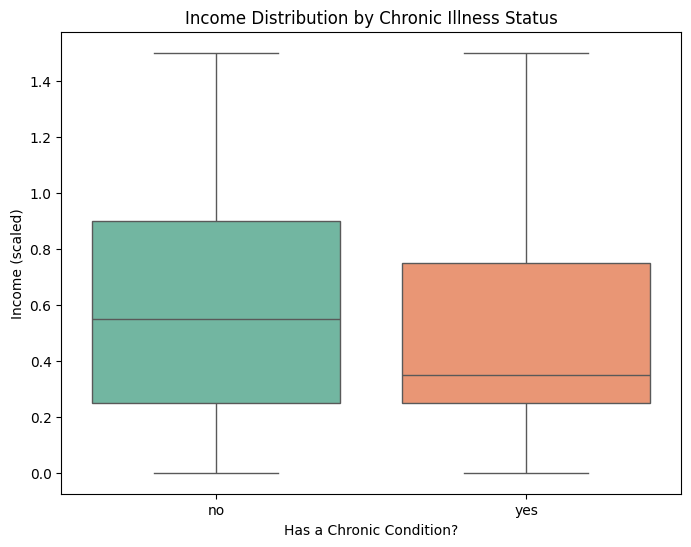

In [20]:
# Income Distribution by Chronic Illness Status

plt.figure(figsize=(8, 6))
sns.boxplot(data=df, x='lchronic', y='income', palette='Set2')
plt.xlabel('Has a Chronic Condition?')
plt.ylabel('Income (scaled)')
plt.title('Income Distribution by Chronic Illness Status')
plt.show()

Insight : Lower income group patients are more likely to be associated with chronic illness.

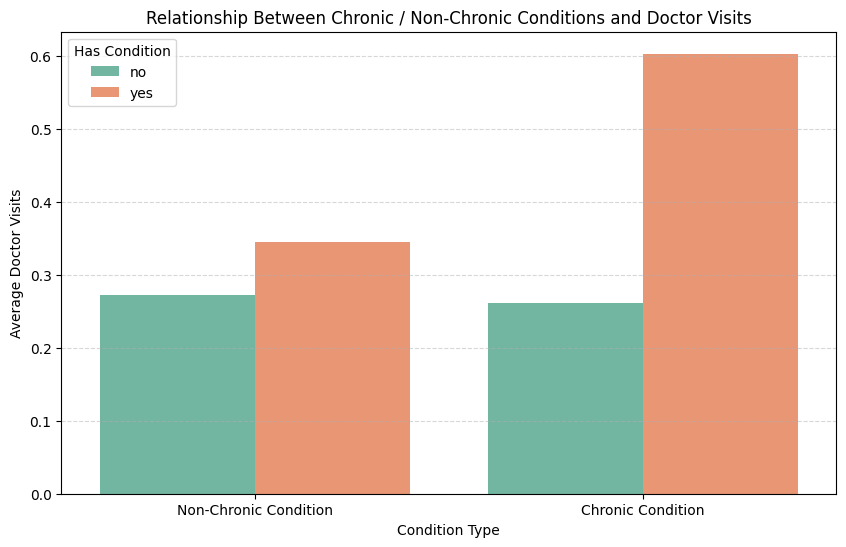

In [28]:
# Melt the dataframe to combine nchronic and lchronic with respect to doctor visits
visits_condition_df = df.melt(
    id_vars=['visits'],
    value_vars=['nchronic', 'lchronic'],
    var_name='Condition Type',
    value_name='Has Condition'
)

# Map for clearer labels
visits_condition_df['Condition Type'] = visits_condition_df['Condition Type'].map({
    'nchronic': 'Non-Chronic Condition',
    'lchronic': 'Chronic Condition'
})

# Group by condition type, active status, and count average visits
plt.figure(figsize=(10, 6))
sns.barplot(
    data=visits_condition_df,
    x='Condition Type',
    y='visits',
    hue='Has Condition',
    palette='Set2',
    errorbar=None
)

plt.xlabel('Condition Type')
plt.ylabel('Average Doctor Visits')
plt.title('Relationship Between Chronic / Non-Chronic Conditions and Doctor Visits')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.show()

Insight : Patients with chronic condition records the highest visits with an average of 0.60 visits, while patients with non-chronic condition record an average of 0.35 visists.

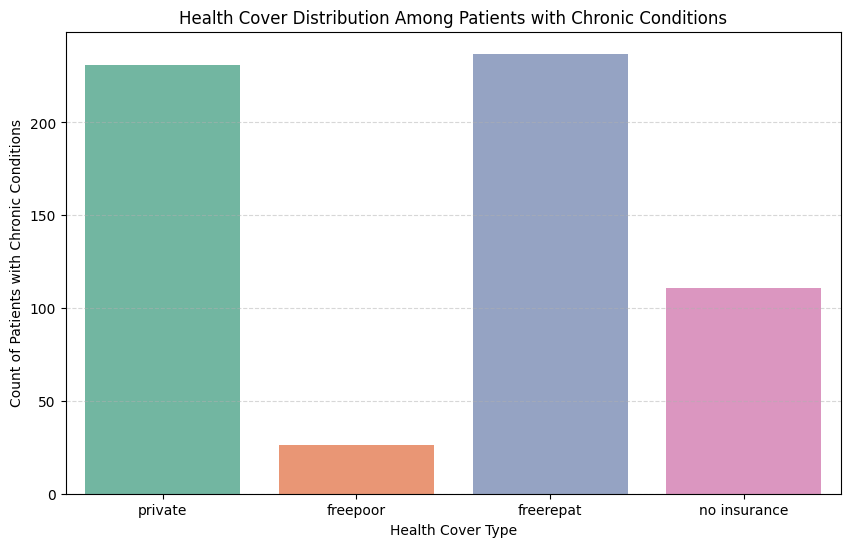

In [36]:
# Health cover distribution among chronic patients
# Filter for patients with chronic conditions ('yes')
chronic_patients = df[df['lchronic'] == 'yes'].copy()

# Calculate who has no coverage at all in the chronic subset
chronic_patients['no insurance'] = ((chronic_patients['private'] == 'no') &
                                    (chronic_patients['freepoor'] == 'no') &
                                    (chronic_patients['freerepat'] == 'no')).map({True: 'yes', False: 'no'})

# Melt to transform health cover columns into rows for easy plotting
chronic_cover_melted = chronic_patients.melt(
    value_vars=['private', 'freepoor', 'freerepat', 'no insurance'],
    var_name='Cover Type',
    value_name='Has Cover'
)

# Keep only active covers
chronic_active_cover = chronic_cover_melted[chronic_cover_melted['Has Cover'] == 'yes']

plt.figure(figsize=(10, 6))
sns.countplot(
    data=chronic_active_cover,
    x='Cover Type',
    hue='Cover Type',
    palette='Set2',
    order=['private', 'freepoor', 'freerepat', 'no insurance'],
    legend=False
)

plt.xlabel('Health Cover Type')
plt.ylabel('Count of Patients with Chronic Conditions')
plt.title('Health Cover Distribution Among Patients with Chronic Conditions')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.show()

Insight : Largest group of chronic patients (around 230) are covered under free coverage due to old age, disability, or veteran status; followed by second largest group of patients (<230) covered with private insurance; while only few having cover due to low income (<30); and around 110 patients have no insurance cover.

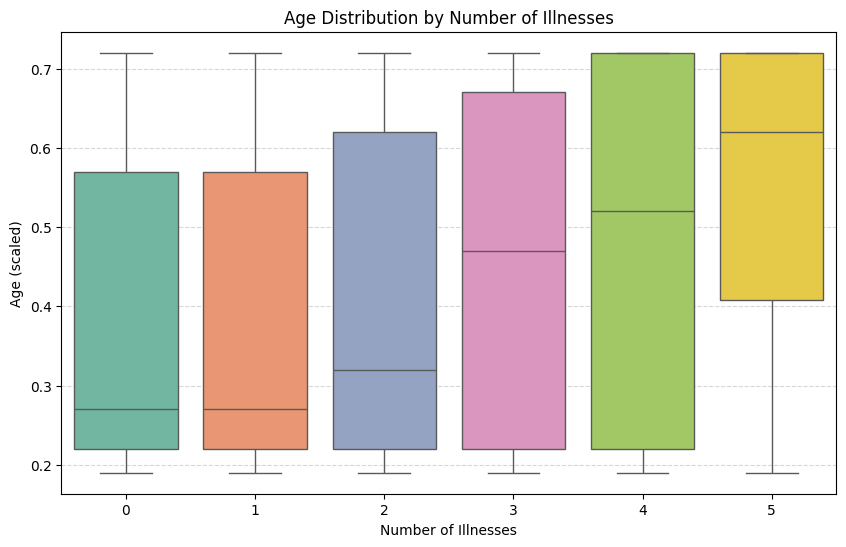

In [31]:
# Relation between Illness & Age using Boxplot for better visibility
plt.figure(figsize=(10, 6))
sns.boxplot(data=df, x='illness', y='age', palette='Set2', hue='illness', legend=False)
plt.xlabel('Number of Illnesses')
plt.ylabel('Age (scaled)')
plt.title('Age Distribution by Number of Illnesses')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.show()

Insight : Younger patients have lower illness, whereas illness count increases in older population.

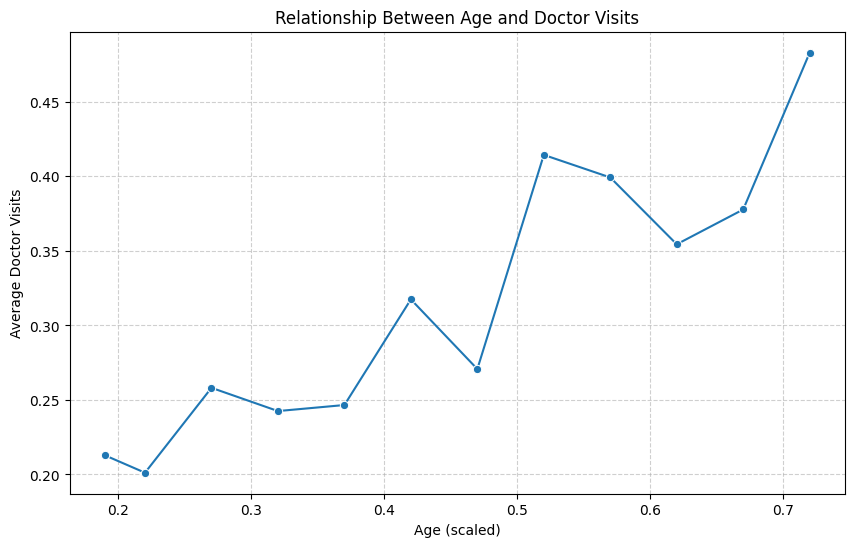

In [37]:
#Relation between age and doctor visits

plt.figure(figsize=(10, 6))
sns.lineplot(data=df, x='age', y='visits', marker='o', errorbar=None)
plt.xlabel('Age (scaled)')
plt.ylabel('Average Doctor Visits')
plt.title('Relationship Between Age and Doctor Visits')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

Insight : Lower age group has lesser number of doctor visits, whereas older age group has higher number of doctor visits.

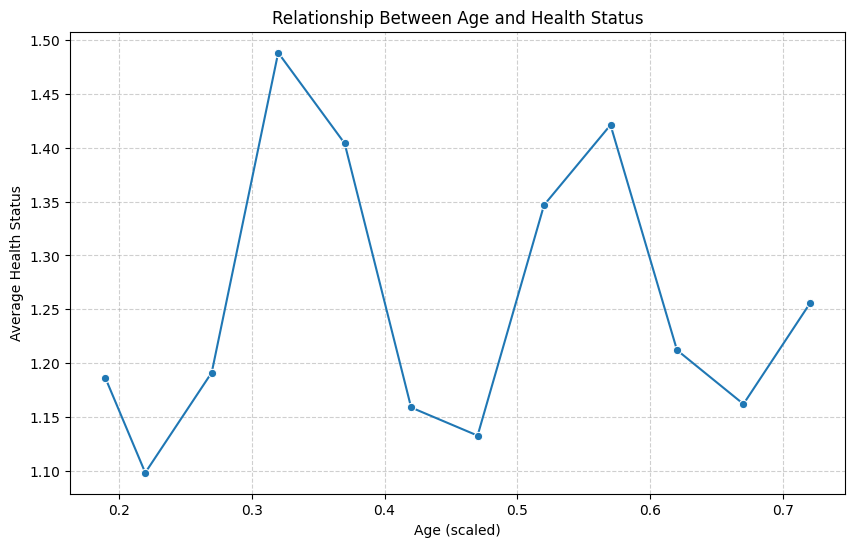

In [35]:
#Age influencing health status

plt.figure(figsize=(10, 6))
sns.lineplot(data=df, x='age', y='health', marker='o', errorbar=None)
plt.xlabel('Age (scaled)')
plt.ylabel('Average Health Status')
plt.title('Relationship Between Age and Health Status')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

Insight : 2 age groups 0.3 and 0.5 - 0.6 show poor health status.

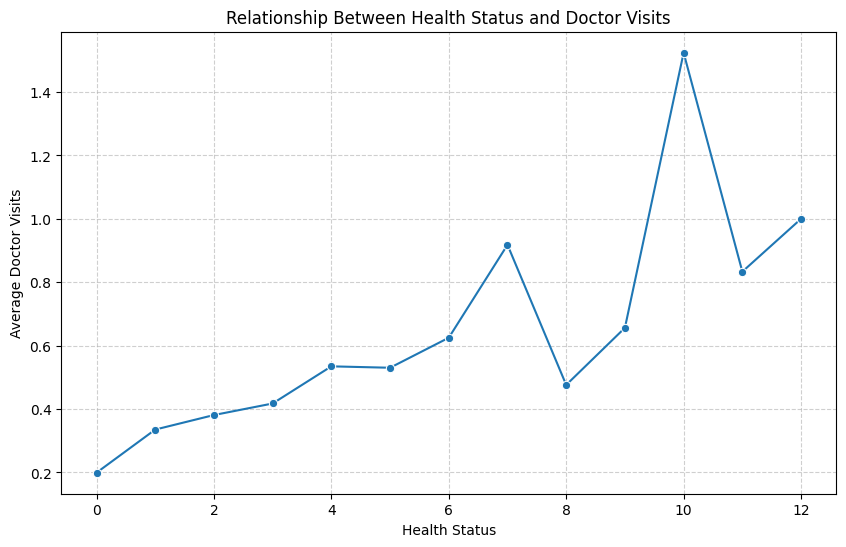

In [33]:
#Health status impacting doctor visits

plt.figure(figsize=(10, 6))
sns.lineplot(data=df, x='health', y='visits', marker='o', errorbar=None)
plt.xlabel('Health Status')
plt.ylabel('Average Doctor Visits')
plt.title('Relationship Between Health Status and Doctor Visits')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

Insight : Patients with poorer health records the highest visit count.

**Insights**



*   4000 patients or more recorded 0 doctor visits in the past 2 weeks, indicative of health conditions not requiring frequent visits.


*   Younger age group patients record less visits whereas older age group patients record higher visits.


*   Females counts for higher overall doctor visits, while males show initial higher visit but dropping gradually with increasing illness.



*   Extreme lower income groups shows highest doctor visits whereas moderate income group show initial higher visits, with doctor visits dropping gradually.
*  Majority doctor visits are associated with 0-1 illness, with younger age having lower illness count and older age group having higher illness count.



*   0 health score (healthier people) has the highest doctor visits.
*   Age group 0.3 and 0.5-0.6 records a poor health score, increasing visits associated with poor health score.


* Patients with private health cover contribute to the highest doctor visits, with more than 2000 patients covered.


*   Chronic illness associates with the highest doctor visits, with lower income group more likely to be associated with chronic as well as non-chronic illness.
*   Patients with chronic illness are majorly covered with either private or freerepat type cover, with a small group having low income cover, and a group of patients having no health cover.







**Recommendations**



*   Optimizing chronic care by introducing telehealth for chronic and older patients.
*  Providing financial counseling to chronic patients with no health cover, helping them transition to safe financial programs.



*   Optimizing staff mangement to accomodate and manage larger elderly population visiting for chronic conditions.
*   Designing and implementing preventive health check-up campaigns targeting sicker men who avoid care and creating more awareness; whereas streamlining hospital management for high female visits.



